In [ ]:
# This is a comment. Python ignores lines starting with #.
print("Hello! I am learning Python for Hydrology.")

# Let's store some hydrological data
precipitation_mm = 770
catchment_area_km2 = 1500
runoff_coefficient = 0.4

# Let's do some math
runoff_volume = precipitation_mm * catchment_area_km2 * runoff_coefficient

print("The total runoff volume is:", runoff_volume)

Hello! I am learning Python for Hydrology.
The total runoff volume is: 462000.0


In [ ]:
# A list of daily rainfall (in mm) for a week in mm
daily_rainfall = [0.0, 5.2, 10.5, 22.1, 4.0, 0.0, 0.0]

print("The rainfall data for the week is:", daily_rainfall)
print("Rainfall on the 4th day (index 3) is:", daily_rainfall[3])

The rainfall data for the week is: [0.0, 5.2, 10.5, 22.1, 4.0, 0.0, 0.0]
Rainfall on the 4th day (index 3) is: 22.1


In [ ]:
# We start a total at zero
total_rain = 0

# We loop through every 'day' in the 'daily_rainfall' list
for rain in daily_rainfall:
    total_rain = total_rain + rain
    print("Adding", rain, "mm. Total is now:", total_rain)

print("The total rainfall for the week was:", total_rain, "mm")

Adding 0.0 mm. Total is now: 0.0
Adding 5.2 mm. Total is now: 5.2
Adding 10.5 mm. Total is now: 15.7
Adding 22.1 mm. Total is now: 37.8
Adding 4.0 mm. Total is now: 41.8
Adding 0.0 mm. Total is now: 41.8
Adding 0.0 mm. Total is now: 41.8
The total rainfall for the week was: 41.8 mm


In [ ]:
# 1. We import the pandas library and give it the nickname 'pd'
import pandas as pd

# 2. We create a dictionary with our hydrology data
data = {
    'Month': ['Jan', 'Feb', 'Mar', 'Apr', 'May'],
    'Precipitation_mm': [45.2, 32.1, 28.5, 15.0, 40.2],
    'Temperature_C': [-2.1, -1.5, 2.0, 8.5, 14.2]
}

# 3. We convert the dictionary into a pandas DataFrame (a table)
df = pd.DataFrame(data)

# 4. We print the table
print(df)

  Month  Precipitation_mm  Temperature_C
0   Jan              45.2           -2.1
1   Feb              32.1           -1.5
2   Mar              28.5            2.0
3   Apr              15.0            8.5
4   May              40.2           14.2


In [ ]:
from google.colab import files
import pandas as pd

# This will pop up a button to upload your file
print("Please upload your smhi_dummy.csv file:")
uploaded = files.upload()

# Now we read the file into a pandas DataFrame
df = pd.read_csv('smhi_dummy.csv')

# Let's look at the first 5 rows of our data
print("\nHere is the data:")
print(df.head())

Please upload your smhi_dummy.csv file:


Saving smhi_dummy.csv to smhi_dummy.csv

Here is the data:
  Date,Precipitation_mm,Temperature_C
0                 2023-01-01,5.2,-1.5
1                 2023-01-02,0.0,-2.1
2                 2023-01-03,12.4,0.5
3                  2023-01-04,8.1,1.2
4                  2023-01-05,0.0,3.0


In [ ]:
import pandas as pd

# This is a real link to a weather dataset on GitHub
url = "https://raw.githubusercontent.com/plotly/datasets/master/2016-weather-data-seattle.csv"

# We load the CSV directly from the internet into a DataFrame
df = pd.read_csv(url)

# Print the first 5 rows
print("Here is the real weather data:")
print(df.head())

Here is the real weather data:
       Date  Max_TemperatureC  Mean_TemperatureC  Min_TemperatureC
0  1/1/1948                10                8.0               7.0
1  1/2/1948                 6                4.0               3.0
2  1/3/1948                 7                4.0               2.0
3  1/4/1948                 7                4.0               2.0
4  1/5/1948                 7                3.0               0.0


In [ ]:
# Let's find days where precipitation was greater than 10mm
heavy_rain = df[df['Precipitationmm'] > 10.0]

# Print the first 5 days of heavy rain
print("Days with heavy rain (>10mm):")
print(heavy_rain.head())

KeyError: 'Precipitationmm'

In [ ]:
# Print the exact names of all columns in the table
print(df.columns.tolist())

['Date', 'Max_TemperatureC', 'Mean_TemperatureC', 'Min_TemperatureC']


In [ ]:
# Let's find the days where the mean temperature was above 20°C
hot_days = df[df['Mean_TemperatureC'] > 20]

# Print the first 5 hot days
print("Days where the mean temperature was above 20°C:")
print(hot_days.head())

Days where the mean temperature was above 20°C:
          Date  Max_TemperatureC  Mean_TemperatureC  Min_TemperatureC
158   6/7/1948                30               23.0              16.0
159   6/8/1948                29               22.0              16.0
160   6/9/1948                26               21.0              14.0
179  6/28/1948                28               21.0              14.0
180  6/29/1948                28               21.0              14.0


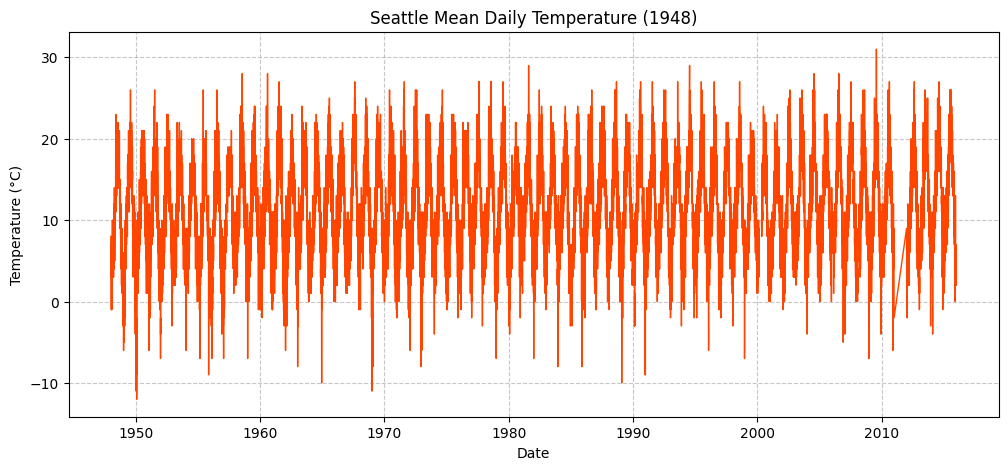

In [ ]:
import matplotlib.pyplot as plt

# 1. Convert the 'Date' column from strings to actual datetime objects
df['Date'] = pd.to_datetime(df['Date'])

# 2. Set the size of the figure (width, height in inches)
plt.figure(figsize=(12, 5))

# 3. Plot the Date on the X-axis and Mean Temperature on the Y-axis
plt.plot(df['Date'], df['Mean_TemperatureC'], color='orangered', linewidth=1)

# 4. Add a title and labels
plt.title('Seattle Mean Daily Temperature (1948)')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')

# 5. Add a grid so it's easier to read
plt.grid(True, linestyle='--', alpha=0.7)

# 6. Show the plot!
plt.show()

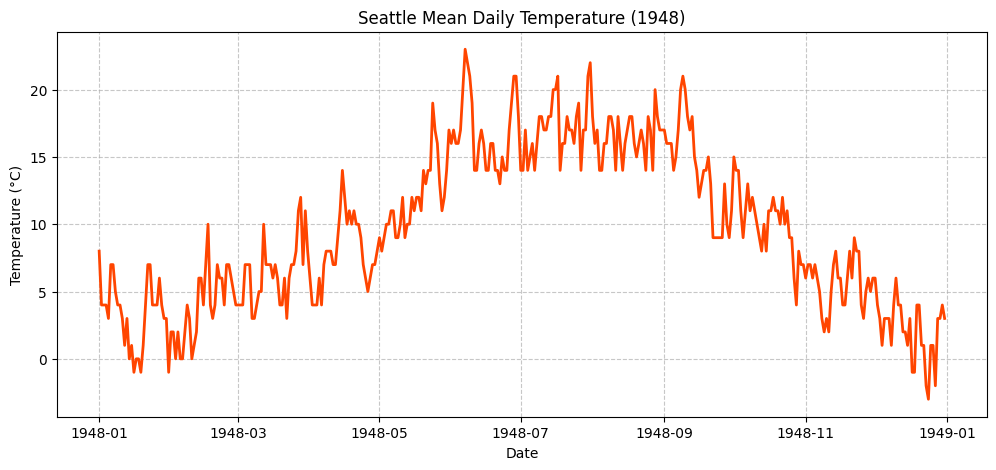

In [ ]:
# Filter the DataFrame to only include rows where the year is 1948
df_1948 = df[df['Date'].dt.year == 1948]

# Now plot the filtered data
plt.figure(figsize=(12, 5))
plt.plot(df_1948['Date'], df_1948['Mean_TemperatureC'], color='orangered', linewidth=2)

plt.title('Seattle Mean Daily Temperature (1948)')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
import requests
import pandas as pd

# Correct URL for Parameter 5 (Daily Precipitation), Station 98230 (Stockholm), Period latest-months
url = "https://opendata-download-metobs.smhi.se/api/version/1.0/parameter/5/station/98230/period/latest-months/data.json"

# Ask the waiter (API) for the data
response = requests.get(url)

if response.status_code == 200:
    print("Success! We connected to SMHI.")
    data = response.json()

    # The 'value' list contains the daily records
    print("\nHere is a sneak peek at the raw JSON data:")
    for item in data['value'][-5:]:
        print(item)
else:
    print("Error connecting to SMHI. Status code:", response.status_code)

Success! We connected to SMHI.

Here is a sneak peek at the raw JSON data:
{'from': 1793426401000, 'to': 1793512800000, 'ref': '2026-10-31', 'value': '0.0', 'quality': 'G'}
{'from': 1793512801000, 'to': 1793599200000, 'ref': '2026-11-01', 'value': '0.1', 'quality': 'G'}
{'from': 1793599201000, 'to': 1793685600000, 'ref': '2026-11-02', 'value': '0.1', 'quality': 'G'}
{'from': 1793685601000, 'to': 1793772000000, 'ref': '2026-11-03', 'value': '0.0', 'quality': 'G'}
{'from': 1793772001000, 'to': 1793858400000, 'ref': '2026-11-04', 'value': '0.0', 'quality': 'G'}


In [ ]:
# Create empty lists to store our clean data
dates = []
precipitation = []

# Loop through the JSON 'value' list
for item in data['value']:
    dates.append(item['ref']) # Extract the date
    precipitation.append(float(item['value'])) # Extract the rain amount

# Create the DataFrame
df_smhi = pd.DataFrame({
    'Date': dates,
    'Precipitation_mm': precipitation
})

# Convert the 'Date' column to actual datetime objects
df_smhi['Date'] = pd.to_datetime(df_smhi['Date'])

# Print the first 5 rows
print("Clean SMHI Precipitation Data for Stockholm (Last 4 Months):")
print(df_smhi.head())

Clean SMHI Precipitation Data for Stockholm (Last 4 Months):
        Date  Precipitation_mm
0 2026-06-27               0.1
1 2026-06-28               2.0
2 2026-06-29               0.0
3 2026-06-30               0.0
4 2026-07-01               0.0


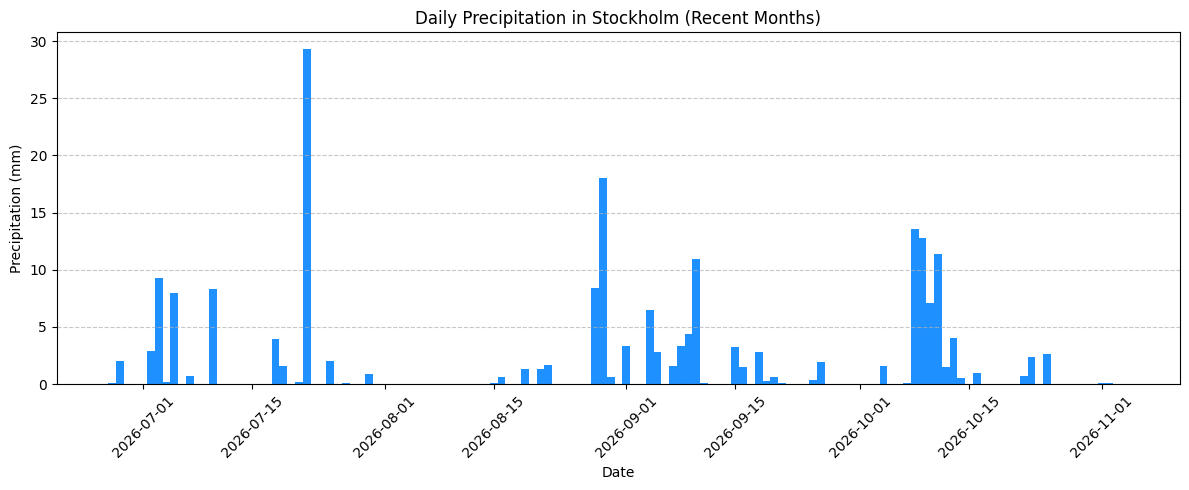

In [ ]:
import matplotlib.pyplot as plt

# Set the figure size
plt.figure(figsize=(12, 5))

# Use plt.bar for precipitation (blue bars)
plt.bar(df_smhi['Date'], df_smhi['Precipitation_mm'], color='dodgerblue', width=1.0)

# Add titles and labels
plt.title('Daily Precipitation in Stockholm (Recent Months)')
plt.xlabel('Date')
plt.ylabel('Precipitation (mm)')

# Rotate the dates so they don't overlap
plt.xticks(rotation=45)

# Add a grid on the y-axis for readability
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# Adjust layout so the dates aren't cut off
plt.tight_layout()

# Show the plot
plt.show()

In [1]:
# Install geopandas (for vector data) and rasterio (for raster data)
!pip install geopandas rasterio

              dissolve  scalerank       featurecla             name name_alt  \
0               0River        1.0            River  Irrawaddy Delta     None   
1  1001Lake Centerline        9.0  Lake Centerline        Tonle Sap     None   
2            1001River        9.0            River        Tonle Sap     None   
3  1002Lake Centerline        9.0  Lake Centerline          Sheksna     None   
4            1002River        9.0            River          Sheksna     None   

   rivernum  note  min_zoom          name_en  min_label  \
0         0  None       2.0  Irrawaddy Delta        3.0   
1      1001  None       7.1        Tonle Sap        8.1   
2      1001  None       7.1        Tonle Sap        8.1   
3      1002  None       7.1          Sheksna        8.1   
4      1002  None       7.1          Sheksna        8.1   

                                            geometry  
0  MULTILINESTRING ((95.4511 17.8205, 95.42766 17...  
1  MULTILINESTRING ((103.68743 13.22468, 103.7133...  

<Figure size 1000x600 with 0 Axes>

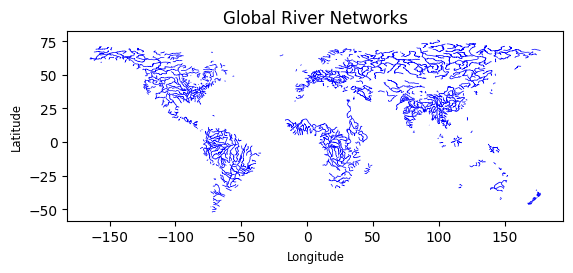

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt

# 1. Load a GeoJSON file directly from a URL
# This is a dataset of the global river network
url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_10m_rivers_lake_centerlines.geojson"

print("Downloading global river data...")
rivers = gpd.read_file(url)

# 2. Let's look at the first 5 rows
print(rivers.head())

# 3. Plot the rivers
plt.figure(figsize=(10, 6))
rivers.plot(color='blue', linewidth=0.5)
plt.title('Global River Networks')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

Opening Raster DEM...
CRS: EPSG:32618
Dimensions: 791 x 718


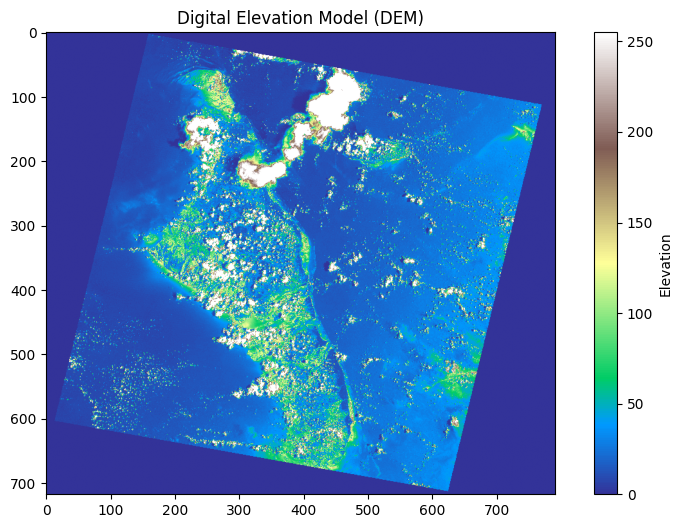

In [3]:
import rasterio
import matplotlib.pyplot as plt

# 1. Open a DEM directly from a URL
dem_url = "https://github.com/rasterio/rasterio/raw/main/tests/data/RGB.byte.tif"

print("Opening Raster DEM...")
with rasterio.open(dem_url) as src:
    # 2. Read the first band (elevation data)
    elevation = src.read(1)

    # 3. Print the metadata (Coordinate Reference System, dimensions, etc.)
    print("CRS:", src.crs)
    print("Dimensions:", src.width, "x", src.height)

    # 4. Plot the elevation
    plt.figure(figsize=(10, 6))
    plt.imshow(elevation, cmap='terrain')
    plt.colorbar(label='Elevation')
    plt.title('Digital Elevation Model (DEM)')
    plt.show()

In [4]:
!pip install rasterstats

In [5]:
import geopandas as gpd
from shapely.geometry import box
import rasterio
from rasterstats import zonal_stats

# 1. Open the DEM we used earlier to get its boundaries
dem_url = "https://github.com/rasterio/rasterio/raw/main/tests/data/RGB.byte.tif"

with rasterio.open(dem_url) as src:
    # Get the bounding box of the raster
    bounds = src.bounds

    # 2. Create a smaller polygon (catchment) in the center of the DEM
    # We take the center coordinates and create a box around it
    center_x = (bounds.left + bounds.right) / 2
    center_y = (bounds.bottom + bounds.top) / 2

    # Create a square polygon (10km x 10km) using shapely's 'box'
    # Note: The units depend on the raster's CRS (usually meters for UTM)
    catchment_poly = box(center_x - 5000, center_y - 5000, center_x + 5000, center_y + 5000)

# 3. Put the polygon into a GeoDataFrame
gdf_catchment = gpd.GeoDataFrame({'name': ['My_Catchment']}, geometry=[catchment_poly], crs=src.crs)

# 4. Use Zonal Stats to extract the mean elevation inside the polygon
stats = zonal_stats(gdf_catchment, dem_url, stats="mean min max")

print("Zonal Statistics Results for the Catchment:")
print(stats)

Zonal Statistics Results for the Catchment:
[{'min': 7.0, 'max': 255.0, 'mean': 53.85739750445633}]


In [6]:
!pip install elevation

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [elevation]



Total Catchment Area: 488.87 km²


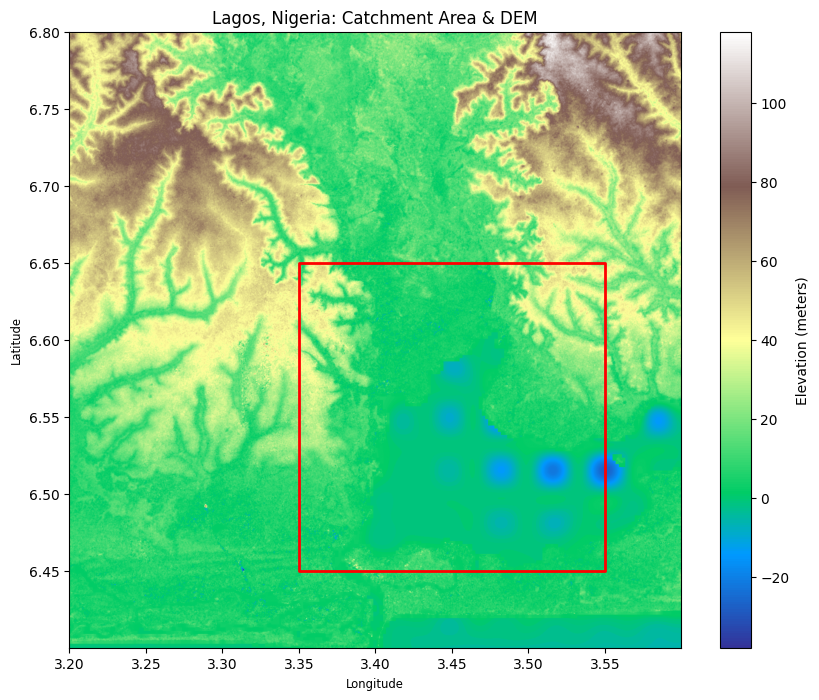

In [7]:
import elevation
import rasterio
import geopandas as gpd
from shapely.geometry import box
import matplotlib.pyplot as plt

# 1. Download the DEM for Lagos, Nigeria
# Coordinates (Min Lon, Min Lat, Max Lon, Max Lat) for Lagos
# Lon: 3.2 to 3.6, Lat: 6.4 to 6.8
print("Downloading DEM for Lagos, Nigeria... (This might take 10-20 seconds)")
bounds = (3.2, 6.4, 3.6, 6.8)
output_file = "lagos_dem.tif"
elevation.clip(bounds=bounds, output=output_file)

# 2. Open the downloaded DEM
with rasterio.open(output_file) as src:
    dem_data = src.read(1)
    bounds = src.bounds
    crs = src.crs

# 3. Create a "Catchment" Polygon (A 0.2 x 0.2 degree box over eastern Lagos)
# We will use this to represent a catchment area
catchment_poly = box(3.35, 6.45, 3.55, 6.65)
gdf_catchment = gpd.GeoDataFrame({'name': ['Lagos_Catchment']}, geometry=[catchment_poly], crs="EPSG:4326")

# 4. Calculate the Area in Square Kilometers
# We must reproject to a metric coordinate system (UTM Zone 31N) to get accurate km²
gdf_metric = gdf_catchment.to_crs(epsg=32631)
area_km2 = gdf_metric.geometry.area / 1e6
print(f"\nTotal Catchment Area: {area_km2.values[0]:.2f} km²")

# 5. Plot the DEM and the Catchment on top
fig, ax = plt.subplots(figsize=(10, 8))

# Plot the elevation data
im = ax.imshow(dem_data, cmap='terrain', extent=[bounds.left, bounds.right, bounds.bottom, bounds.top])
plt.colorbar(im, ax=ax, label='Elevation (meters)')

# Plot the catchment polygon
gdf_catchment.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=2)

# Add labels
ax.set_title('Lagos, Nigeria: Catchment Area & DEM')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.show()


Total Ajah Catchment Area: 44.01 km²


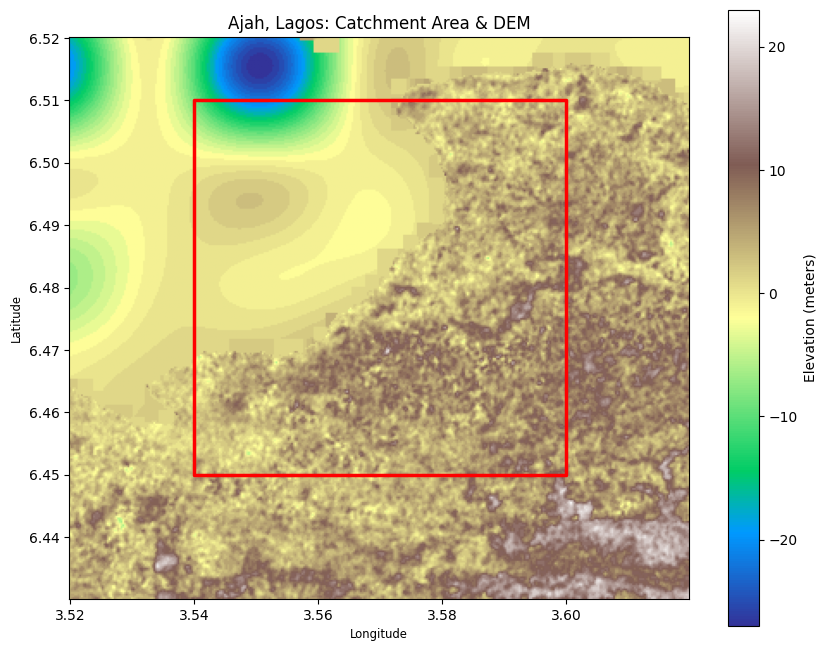

In [8]:
import elevation
import rasterio
import geopandas as gpd
from shapely.geometry import box
import matplotlib.pyplot as plt

# 1. Download the DEM for Ajah, Lagos
# Coordinates for Ajah (Longitude Min, Latitude Min, Longitude Max, Latitude Max)
print("Downloading DEM for Ajah, Lagos... (This might take 10-20 seconds)")
bounds = (3.52, 6.43, 3.62, 6.52)
output_file = "ajah_dem.tif"
elevation.clip(bounds=bounds, output=output_file)

# 2. Open the downloaded DEM
with rasterio.open(output_file) as src:
    dem_data = src.read(1)
    bounds = src.bounds
    crs = src.crs

# 3. Create a Catchment Polygon for Ajah
# We draw a box that stays mostly on the landmass to avoid the ocean
catchment_poly = box(3.54, 6.45, 3.60, 6.51)
gdf_catchment = gpd.GeoDataFrame({'name': ['Ajah_Catchment']}, geometry=[catchment_poly], crs="EPSG:4326")

# 4. Calculate the Area in Square Kilometers
# Reproject to UTM Zone 31N (EPSG:32631) for accurate metric area calculation
gdf_metric = gdf_catchment.to_crs(epsg=32631)
area_km2 = gdf_metric.geometry.area / 1e6
print(f"\nTotal Ajah Catchment Area: {area_km2.values[0]:.2f} km²")

# 5. Plot the DEM and the Catchment
fig, ax = plt.subplots(figsize=(10, 8))

# Plot elevation (using a terrain colormap)
im = ax.imshow(dem_data, cmap='terrain', extent=[bounds.left, bounds.right, bounds.bottom, bounds.top])
plt.colorbar(im, ax=ax, label='Elevation (meters)')

# Plot the catchment polygon
gdf_catchment.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=2.5)

# Add labels
ax.set_title('Ajah, Lagos: Catchment Area & DEM')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.show()

In [1]:
!pip install "numpy<1.26.4"

  Using cached numpy-1.26.3.tar.gz (15.7 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for numpy: filename=numpy-1.26.3-cp313-cp313-linux_x86_64.whl size=25913676 sha256=f0585390606a19829d25efac34e23a43d011d7a39d1c74ab10ced4ab617fd0a2
  Stored in directory: /root/.cache/pip/wheels/cd/80/5a/8deaed51e64f65a6fa8d0bd4078495e3d242f13a65f6a627d0
Successfully built numpy
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.3 which is incompatible.
tobler 0.14.0 requires numpy>=2.0, but you

In [9]:
!pip install pysheds

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pysheds]


Filling sinks...
Calculating flow direction...
Calculating flow accumulation...


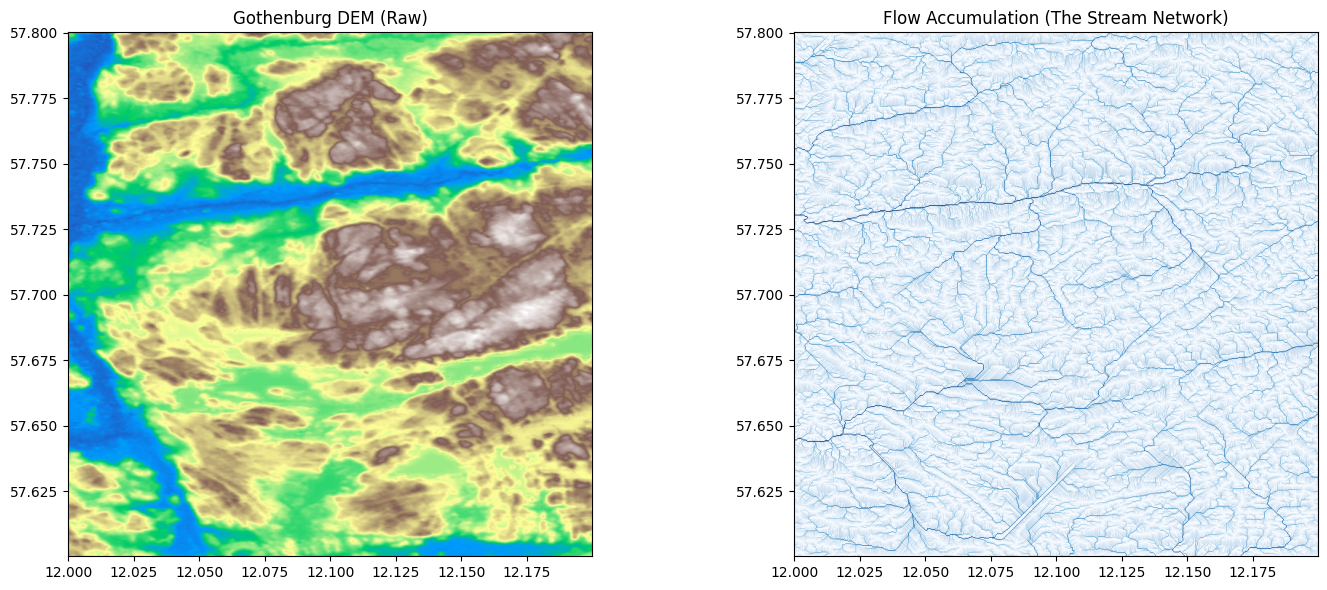

In [1]:
import matplotlib.pyplot as plt
from pysheds.grid import Grid
import elevation

# 1. Download a DEM for Gothenburg (The exact same step you did manually in QGIS)
print("Downloading Gothenburg DEM...")
bounds = (12.0, 57.6, 12.2, 57.8) # Small area around Gothenburg
elevation.clip(bounds=bounds, output='gothenburg_dem.tif')

# 2. Load the DEM into pysheds
grid = Grid.from_raster('gothenburg_dem.tif')
dem = grid.read_raster('gothenburg_dem.tif')

# 3. FILL SINKS (Equivalent to QGIS r.fill.dir)
print("Filling sinks...")
pit_filled_dem = grid.fill_pits(dem)
flooded_dem = grid.fill_depressions(pit_filled_dem)
inflated_dem = grid.resolve_flats(flooded_dem)

# 4. FLOW DIRECTION (Equivalent to QGIS r.fill.dir output aspect)
print("Calculating flow direction...")
fdir = grid.flowdir(inflated_dem)

# 5. FLOW ACCUMULATION (Equivalent to QGIS r.watershed)
print("Calculating flow accumulation...")
acc = grid.accumulation(fdir)

# 6. PLOT THE RESULTS
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# Plot the original DEM
ax[0].imshow(dem, cmap='terrain', extent=grid.extent)
ax[0].set_title('Gothenburg DEM (Raw)')

# Plot the Flow Accumulation (The "rivers")
# We use a logarithmic scale because accumulation numbers get huge
im = ax[1].imshow(acc, cmap='Blues', extent=grid.extent, norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=acc.max()))
ax[1].set_title('Flow Accumulation (The Stream Network)')

plt.tight_layout()
plt.show()

Extracting catchment for point: 12.147, 57.725


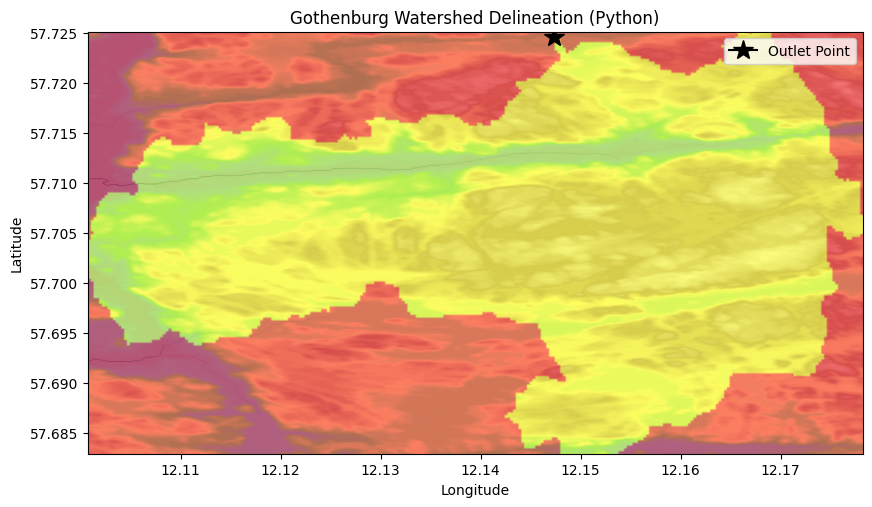

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the Pour Point (Outlet)
x_pour, y_pour = 12.15, 57.725

# 2. Snap the point to the nearest high-accumulation cell
x_snap, y_snap = grid.snap_to_mask(acc > 500, (x_pour, y_pour))

# 3. Extract the Catchment
print(f"Extracting catchment for point: {x_snap:.3f}, {y_snap:.3f}")
catch = grid.catchment(x=x_snap, y=y_snap, fdir=fdir, xytype='coordinate')

# 4. Clip the view to the catchment area
grid.clip_to(catch)
catch_view = grid.view(catch, dtype=np.uint8)

# 5. Plot the results
fig, ax = plt.subplots(figsize=(10, 8))

# Plot the DEM (Terrain)
plt.imshow(inflated_dem, cmap='terrain', extent=grid.extent)

# Plot the Flow Accumulation (Blues) lightly in the background
plt.imshow(acc, cmap='Blues', extent=grid.extent, alpha=0.4)

# Plot the Catchment Boundary in Red
plt.imshow(catch_view, cmap='autumn', extent=grid.extent, alpha=0.5)

# Mark the outlet point with a star
plt.plot(x_snap, y_snap, marker='*', color='black', markersize=15, label='Outlet Point')

plt.title('Gothenburg Watershed Delineation (Python)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.show()